# 04 · The Arena

All five methods — **popularity, user-kNN, item-kNN, matrix factorization,
content-based** — on one honest split, scored across *everything*: the ranking
metrics (precision@k, recall@k, NDCG@k, MAP, coverage) **and** the beyond-accuracy
metrics (novelty, diversity, popularity bias) that accuracy quietly hides.

The scoreboard delivers the uncomfortable, two-sided verdict this whole project is
about.

In [1]:
# --- make the notebook runnable from anywhere: find the repo root, add to path, chdir ---
import os
import sys
from pathlib import Path

_root = Path.cwd()
while not (_root / "pyproject.toml").exists() and _root != _root.parent:
    _root = _root.parent
sys.path.insert(0, str(_root))
os.chdir(_root)

%matplotlib inline
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 120)

from src.artifacts import save_figure, save_json
from src.config import get_settings

SETTINGS = get_settings()
print("project root:", _root)
print("seed:", SETTINGS.seed, "| top_k:", SETTINGS.top_k)

project root: /workspaces/recommender_101
seed: 42 | top_k: 10


In [2]:
from src.data.ratings import load_movielens
from src.evaluation.comparison import run_arena
from src.evaluation.splits import leave_last_out
from src.recommenders import build_default_recommenders

data = load_movielens()
split = leave_last_out(
    data.matrix, n_holdout=SETTINGS.split.n_holdout, min_train=SETTINGS.split.min_train,
    timestamps=data.timestamps, seed=SETTINGS.seed,
)
recommenders = build_default_recommenders(item_features=data.item_features, settings=SETTINGS)
board = run_arena(recommenders, split, k=SETTINGS.top_k, item_features=data.item_features)
save_json(board, "04_scoreboard")
board.round(4)

,precision@k,recall@k,ndcg@k,map,coverage,novelty,pop_bias,diversity
method,,,,,,,,
popularity,0.0072,0.0361,0.0209,0.0120,0.0125,1.4271,231.6143,0.7003
user_knn,0.0123,0.0615,0.0356,0.0210,0.0313,1.8497,183.3970,0.6972
item_knn,0.0138,0.0689,0.0400,0.0236,0.0745,2.4656,130.3716,0.6821
matrix_factorization,0.0021,0.0107,0.0065,0.0037,0.0568,4.7759,50.2967,0.6343
content,0.0007,0.0033,0.0013,0.0004,0.1517,7.1502,11.9828,0.1091


## The honest verdict

Read the scoreboard one column at a time and the two-sided story appears:

- **Accuracy (precision/recall/NDCG/MAP):** neighbourhood CF (item- and user-based)
  leads; **matrix factorization, trained on explicit ratings, trails the popularity
  baseline** (the ranking gap from notebook 03); content-based is weakest.
- **Coverage:** popularity is *last by a mile* — it recommends the same few
  blockbusters to everyone — while content and the personalized methods explore far
  more of the catalog.
- **Novelty & diversity:** popularity is the *worst* at surfacing anything
  non-obvious; content-based is the most novel and least popularity-biased.

So "who wins?" has no single answer — it depends entirely on which column you
believe matters, which is exactly why you report **all** of them, starting with the
popularity line.

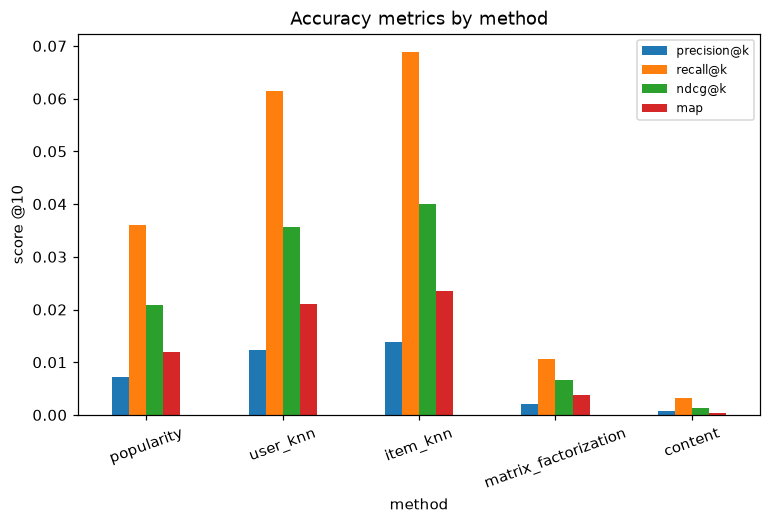

In [3]:
acc = board[["precision@k", "recall@k", "ndcg@k", "map"]]
fig, ax = plt.subplots(figsize=(8, 4.5))
acc.plot(kind="bar", ax=ax)
ax.set_ylabel(f"score @{SETTINGS.top_k}")
ax.set_title("Accuracy metrics by method")
ax.tick_params(axis="x", rotation=20)
ax.legend(fontsize=8)
save_figure(fig, "04_accuracy_metrics")
plt.show()

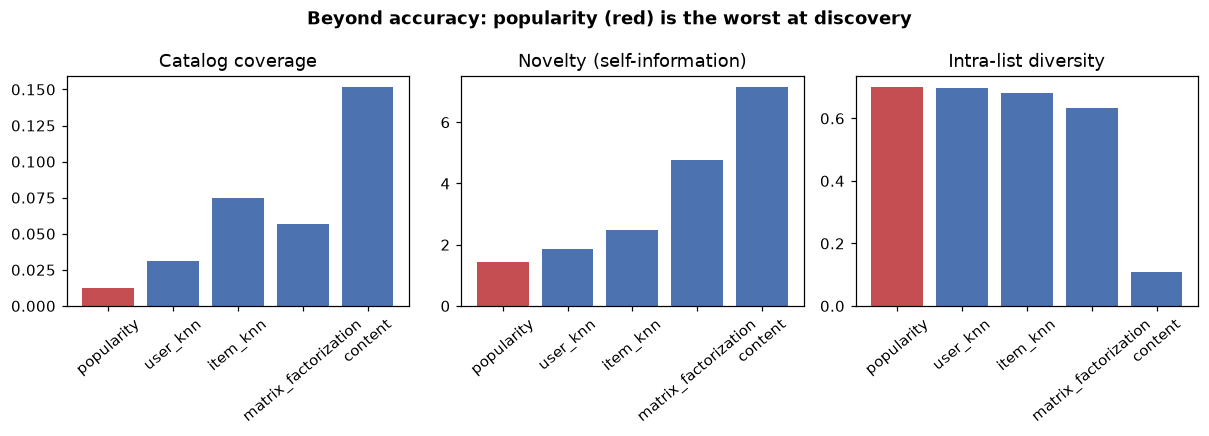

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for ax, col, title in zip(
    axes, ["coverage", "novelty", "diversity"],
    ["Catalog coverage", "Novelty (self-information)", "Intra-list diversity"],
):
    colors = ["#C44E52" if m == "popularity" else "#4C72B0" for m in board.index]
    ax.bar(board.index, board[col], color=colors)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=40)
fig.suptitle("Beyond accuracy: popularity (red) is the worst at discovery", fontweight="bold")
fig.tight_layout()
save_figure(fig, "04_beyond_accuracy")
plt.show()

In [5]:
# which methods beat the popularity baseline, metric by metric?
pop = board.loc["popularity"]
higher_is_better = ["precision@k", "recall@k", "ndcg@k", "map", "coverage", "novelty", "diversity"]
verdict = {}
for metric in higher_is_better:
    winners = [m for m in board.index if m != "popularity" and board.loc[m, metric] > pop[metric]]
    verdict[metric] = {"popularity": float(pop[metric]), "methods_that_beat_it": winners}
save_json(verdict, "04_vs_popularity")
pd.DataFrame({m: {"beats popularity": ", ".join(v["methods_that_beat_it"]) or "— none —"}
              for m, v in verdict.items()}).T

,beats popularity
precision@k,"user_knn, item_knn"
recall@k,"user_knn, item_knn"
ndcg@k,"user_knn, item_knn"
map,"user_knn, item_knn"
coverage,"user_knn, item_knn, matrix_factorization, content"
novelty,"user_knn, item_knn, matrix_factorization, content"
diversity,— none —


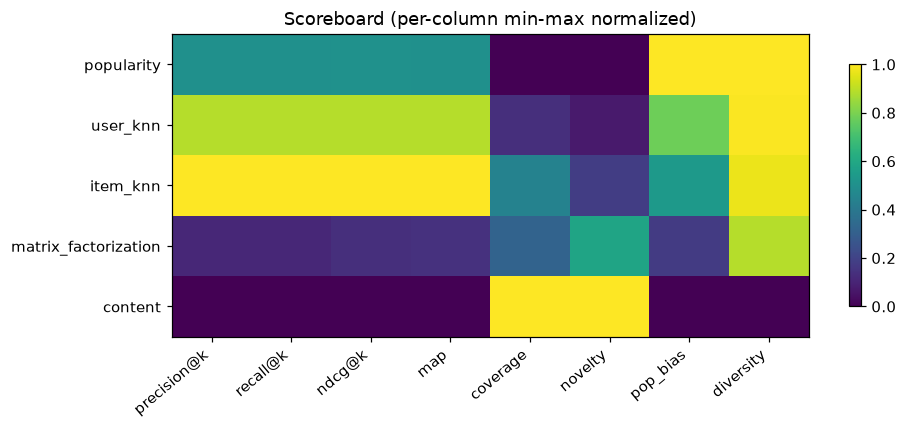

In [6]:
# normalized scoreboard heatmap (each column min-max scaled; brighter = higher)
norm = (board - board.min()) / (board.max() - board.min())
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(norm.values, aspect="auto", cmap="viridis")
ax.set_xticks(range(len(board.columns))); ax.set_xticklabels(board.columns, rotation=40, ha="right")
ax.set_yticks(range(len(board.index))); ax.set_yticklabels(board.index)
ax.set_title("Scoreboard (per-column min-max normalized)")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
save_figure(fig, "04_scoreboard_heatmap")
plt.show()

## Takeaway

There is no free lunch and no single winner. Popularity is genuinely competitive on
accuracy *and* beats our explicit-rating matrix factorization there — yet it is the
worst recommender in the room for discovery. The methods that explore the catalog
pay for it in raw hit-rate. **Report the whole scoreboard, popularity first, and be
explicit about which trade-off you are optimising.**

**Next:** [05 · Cold Start](05_cold_start.ipynb) — the one place the personalized
methods don't just trail popularity, they *break entirely*.